# Tarea #3 — Clasificación binaria con Apache Spark (PySpark)

## Predicción de abandono de clientes (*customer churn*)

### Dominio del problema
Este notebook entrena **dos modelos de clasificación binaria** con Apache Spark
para predecir el **abandono de clientes** (*churn*) de un servicio. El objetivo
de negocio es identificar con anticipación qué clientes tienen alta probabilidad
de abandonar, de modo que el equipo comercial pueda tomar acciones de retención.

Se utiliza **PostgreSQL** (en contenedor) como almacenamiento intermedio: el
conjunto limpio se escribe en la tabla `tarea3` y las predicciones de cada modelo
en las tablas `modelo1` y `modelo2`.

### Descripción de los atributos
El conjunto de datos (`../data/dataset.csv`) contiene 10 000 registros con las
siguientes columnas:

| Columna | Tipo | Descripción |
|---|---|---|
| `id` | string (UUID) | Identificador único del cliente. **NO es una característica**: se conserva solo como llave y no se usa para entrenar. |
| `edad` | entero | Edad del cliente en años. |
| `gasto_mensual` | decimal | Gasto mensual promedio del cliente (unidades monetarias). |
| `tickets_soporte` | entero | Cantidad de tickets de soporte abiertos por el cliente. |
| `meses_cliente` | entero | Antigüedad del cliente en meses. |
| `usa_app` | entero (0/1) | Indica si el cliente usa la aplicación móvil (1) o no (0). |
| `etiqueta` | entero (0/1) | **Variable objetivo / de predicción.** |

### Variable de predicción
La variable que se desea predecir es **`etiqueta`**, una variable binaria:

- **`0` = el cliente se queda** (no abandona).
- **`1` = el cliente abandona** (*churn*).

Las **características** (features) utilizadas por los modelos son:
`edad`, `gasto_mensual`, `tickets_soporte`, `meses_cliente` y `usa_app`.


In [1]:
# Dependencias
%matplotlib inline

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType, DoubleType
)
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator, MulticlassClassificationEvaluator
)
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

import matplotlib.pyplot as plt
import seaborn as sns
import os

# Carpeta de salida para las figuras (montada como ./output en el host)
os.makedirs("../output", exist_ok=True)
print("Dependencias importadas correctamente.")

Dependencias importadas correctamente.


In [2]:
# Constantes del proyecto (semilla fija para reproducibilidad)
SEED = 27

FEATURE_COLS = ["edad", "gasto_mensual", "tickets_soporte", "meses_cliente", "usa_app"]
DB_COLS = ["id", "edad", "gasto_mensual", "tickets_soporte",
           "meses_cliente", "usa_app", "etiqueta"]

# Conexión JDBC a PostgreSQL (contenedor 'postgres')
JDBC_URL = "jdbc:postgresql://postgres:5432/tarea3"
JDBC_PROPS = {"user": "spark", "password": "spark", "driver": "org.postgresql.Driver"}

# Jars incluidos en la imagen (se conserva la configuración original)
JARS = ("/opt/venv/lib/python3.10/site-packages/pyspark/jars/"
        "elasticsearch-spark-30_2.12-8.14.3.jar,"
        "/opt/venv/lib/python3.10/site-packages/pyspark/jars/postgresql-42.7.3.jar")

print("Semilla fija SEED =", SEED)
print("Características (features):", FEATURE_COLS)
print("Columnas en base de datos:", DB_COLS)

Semilla fija SEED = 27
Características (features): ['edad', 'gasto_mensual', 'tickets_soporte', 'meses_cliente', 'usa_app']
Columnas en base de datos: ['id', 'edad', 'gasto_mensual', 'tickets_soporte', 'meses_cliente', 'usa_app', 'etiqueta']


In [3]:
# SparkSession conservando la configuración de jars (driver JDBC de PostgreSQL)
spark = (
    SparkSession.builder
    .appName("M4-T3")
    .config("spark.jars", JARS)
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("SparkSession lista. Versión de Spark:", spark.version)

26/10/27 00:25:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


SparkSession lista. Versión de Spark: 3.5.1


## 1. Carga y limpieza de datos

Se define un **esquema explícito** (`StructType`) para la lectura del CSV, sin usar
`inferSchema`. Esto garantiza que los tipos sean deterministas y evita que Spark
tenga que recorrer los datos para adivinarlos.

In [4]:
# Esquema explícito (sin inferSchema)
schema = StructType([
    StructField("id",              StringType(),  True),
    StructField("edad",            IntegerType(), True),
    StructField("gasto_mensual",   DoubleType(),  True),
    StructField("tickets_soporte", IntegerType(), True),
    StructField("meses_cliente",   IntegerType(), True),
    StructField("usa_app",         IntegerType(), True),
    StructField("etiqueta",        IntegerType(), True),
])

df = spark.read.csv("../data/dataset.csv", header=True, schema=schema)

print("Esquema del DataFrame:")
df.printSchema()

Esquema del DataFrame:
root
 |-- id: string (nullable = true)
 |-- edad: integer (nullable = true)
 |-- gasto_mensual: double (nullable = true)
 |-- tickets_soporte: integer (nullable = true)
 |-- meses_cliente: integer (nullable = true)
 |-- usa_app: integer (nullable = true)
 |-- etiqueta: integer (nullable = true)



In [5]:
# Evidencia de carga: cantidad de filas y primeras observaciones
print("Número de registros cargados:", df.count())
df.show(5, truncate=False)

Número de registros cargados: 10000


+------------------------------------+----+-------------+---------------+-------------+-------+--------+
|id                                  |edad|gasto_mensual|tickets_soporte|meses_cliente|usa_app|etiqueta|
+------------------------------------+----+-------------+---------------+-------------+-------+--------+
|6fa0d32d-6e59-4903-ab07-725685422225|70  |888.09       |2              |10           |0      |0       |
|aaedcf2b-68b6-43f8-acfb-2d677f2c3903|57  |449.99       |10             |8            |0      |0       |
|34cc99f5-1032-4a80-b2af-3311552aeb41|35  |47.53        |1              |13           |0      |0       |
|128fde75-d1de-47f2-a870-7bbf202041b3|62  |42.53        |7              |76           |1      |0       |
|97ac9410-58f3-4eeb-9bbf-b0496499b632|38  |360.08       |8              |70           |1      |0       |
+------------------------------------+----+-------------+---------------+-------------+-------+--------+
only showing top 5 rows



In [6]:
# Conteo de valores nulos por columna
nulos = df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df.columns
])
print("Valores nulos por columna:")
nulos.show()

Valores nulos por columna:


+---+----+-------------+---------------+-------------+-------+--------+
| id|edad|gasto_mensual|tickets_soporte|meses_cliente|usa_app|etiqueta|
+---+----+-------------+---------------+-------------+-------+--------+
|  0|   0|            0|              0|            0|      0|       0|
+---+----+-------------+---------------+-------------+-------+--------+



In [7]:
# Conteo de duplicados
total = df.count()
distintos_id = df.select("id").distinct().count()
filas_distintas = df.distinct().count()
print("Filas totales:", total)
print("IDs distintos:", distintos_id, "-> IDs duplicados:", total - distintos_id)
print("Filas completamente distintas:", filas_distintas,
      "-> filas duplicadas:", total - filas_distintas)

Filas totales: 10000
IDs distintos: 10000 -> IDs duplicados: 0
Filas completamente distintas: 10000 -> filas duplicadas: 0


In [8]:
# Limpieza: eliminar duplicados por 'id' y descartar filas con nulos
df_limpio = df.dropDuplicates(["id"]).na.drop()

print("Registros después de la limpieza:", df_limpio.count())
print("Nulos restantes por columna:")
df_limpio.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_limpio.columns
]).show()

Registros después de la limpieza: 10000
Nulos restantes por columna:


+---+----+-------------+---------------+-------------+-------+--------+
| id|edad|gasto_mensual|tickets_soporte|meses_cliente|usa_app|etiqueta|
+---+----+-------------+---------------+-------------+-------+--------+
|  0|   0|            0|              0|            0|      0|       0|
+---+----+-------------+---------------+-------------+-------+--------+



## 2. Gráficos y estadísticas descriptivas

Antes del entrenamiento se exploran los datos: estadísticas descriptivas, balance
de clases, distribuciones de las variables numéricas y correlaciones. Las figuras
se guardan en `../output/` y se muestran en línea.

In [9]:
# Estadísticas descriptivas de las variables numéricas
df_limpio.select(FEATURE_COLS + ["etiqueta"]).summary().show()

26/10/27 00:26:00 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+
|summary|              edad|     gasto_mensual|  tickets_soporte|    meses_cliente|           usa_app|          etiqueta|
+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+
|  count|             10000|             10000|            10000|            10000|             10000|             10000|
|   mean|           46.4805|501.43390699999856|           7.4697|          60.9161|            0.4962|            0.4121|
| stddev|16.749145444986528| 283.5431698630083|4.619806940946462|34.58310946019734|0.5000105609445729|0.4922375643751473|
|    min|                18|             10.25|                0|                1|                 0|                 0|
|    25%|                32|            256.47|                3|               31|                 0|                 0|
|    50%|               

In [10]:
# Balance de clases de la variable objetivo 'etiqueta'
balance = df_limpio.groupBy("etiqueta").count().orderBy("etiqueta")
balance.show()

total_limpio = df_limpio.count()
for fila in balance.collect():
    pct = 100.0 * fila["count"] / total_limpio
    print(f"Clase {fila['etiqueta']}: {fila['count']} registros ({pct:.2f}%)")

+--------+-----+
|etiqueta|count|
+--------+-----+
|       0| 5879|
|       1| 4121|
+--------+-----+



Clase 0: 5879 registros (58.79%)
Clase 1: 4121 registros (41.21%)


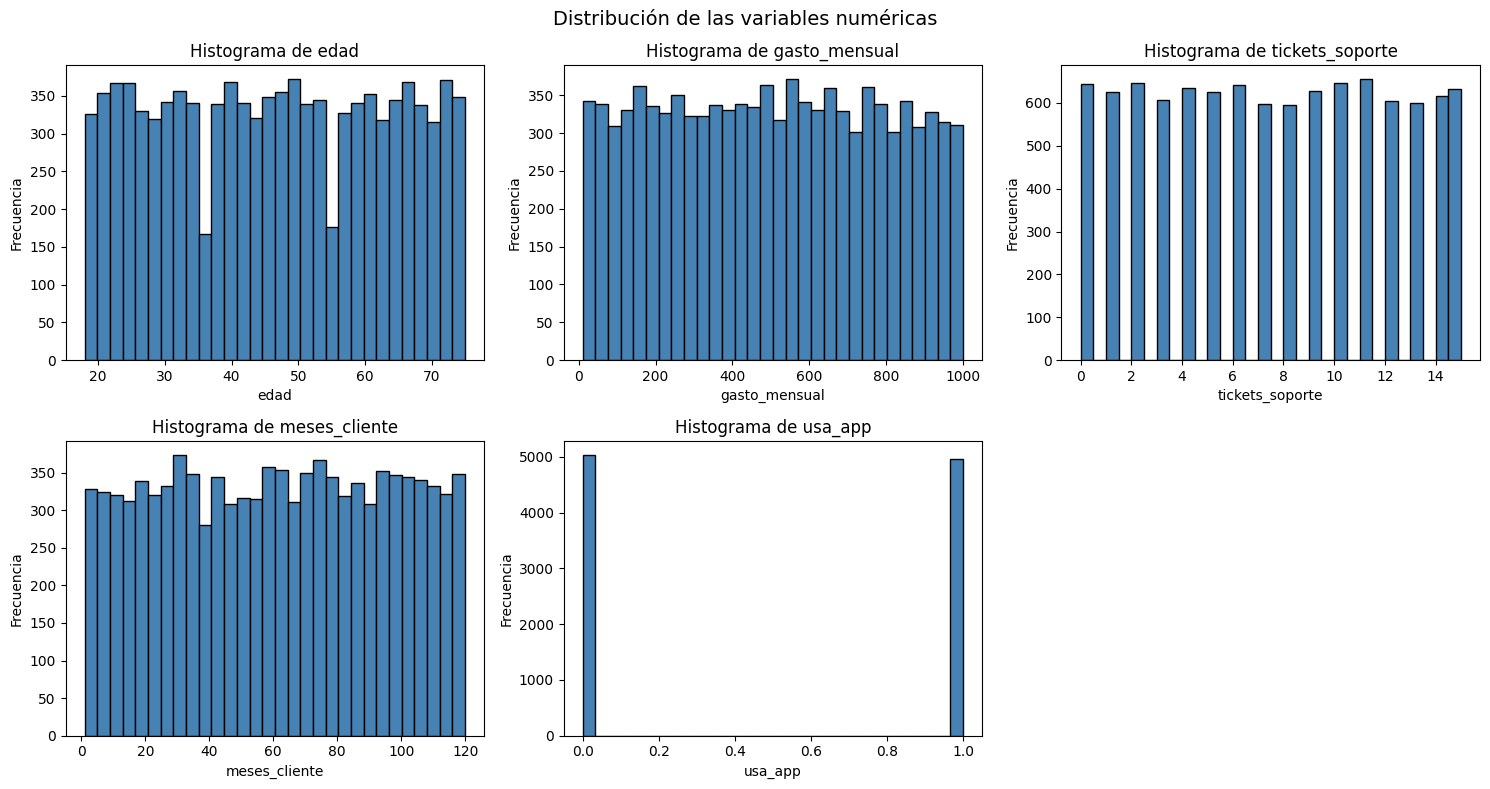

In [11]:
# Pasamos a pandas para graficar (el conjunto es pequeño: ~10 000 filas)
pdf = df_limpio.select(FEATURE_COLS + ["etiqueta"]).toPandas()

# Histogramas de las variables numéricas
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(FEATURE_COLS):
    axes[i].hist(pdf[col], bins=30, color="steelblue", edgecolor="black")
    axes[i].set_title(f"Histograma de {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frecuencia")
axes[-1].axis("off")
fig.suptitle("Distribución de las variables numéricas", fontsize=14)
fig.tight_layout()
fig.savefig("../output/histogramas.png", dpi=100, bbox_inches="tight")
plt.show()

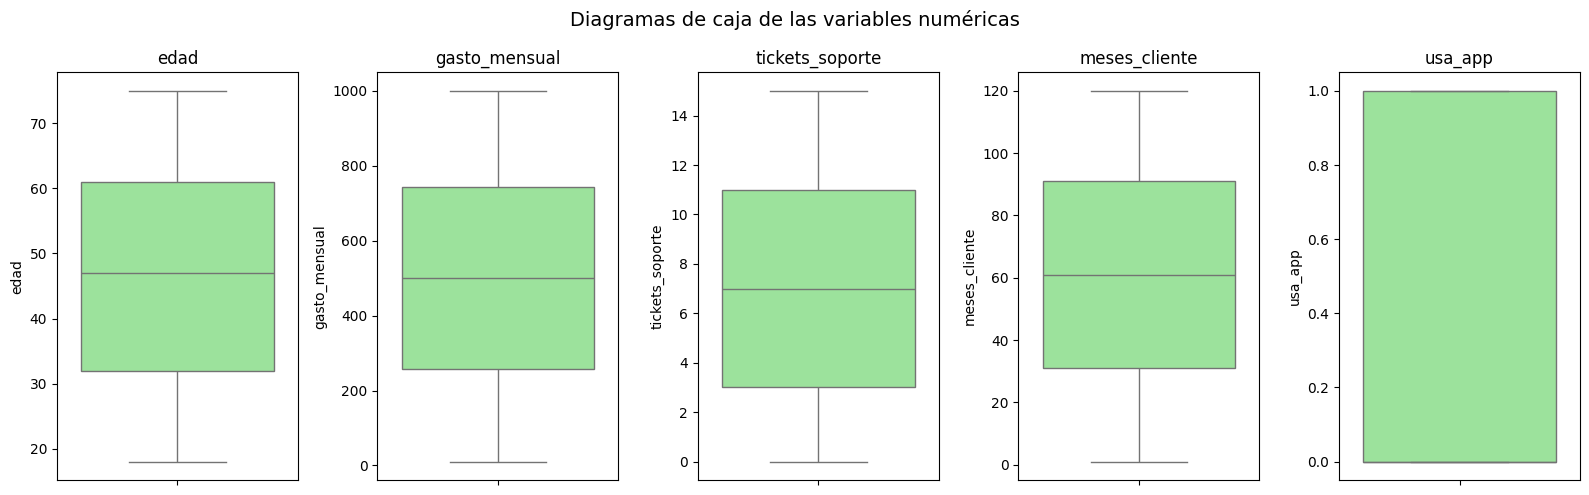

In [12]:
# Boxplots de las variables numéricas (detección de escala y atípicos)
fig, axes = plt.subplots(1, len(FEATURE_COLS), figsize=(16, 5))
for i, col in enumerate(FEATURE_COLS):
    sns.boxplot(y=pdf[col], ax=axes[i], color="lightgreen")
    axes[i].set_title(col)
fig.suptitle("Diagramas de caja de las variables numéricas", fontsize=14)
fig.tight_layout()
fig.savefig("../output/boxplots.png", dpi=100, bbox_inches="tight")
plt.show()

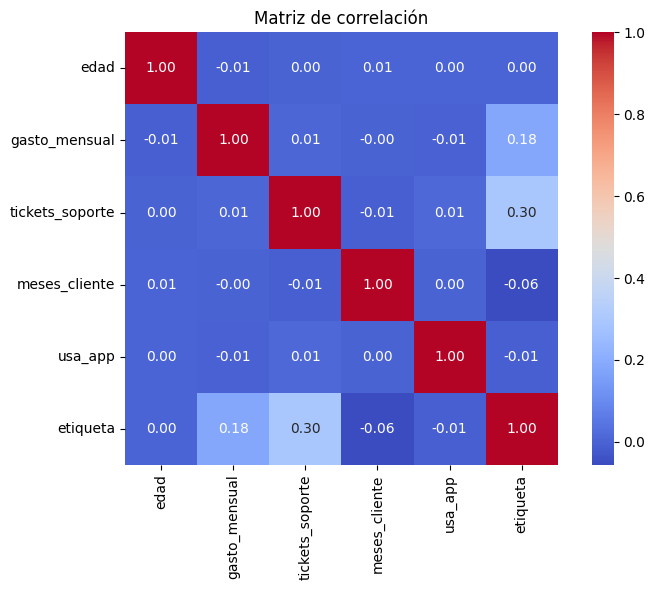

In [13]:
# Matriz de correlación (features + etiqueta)
corr = pdf.corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True, ax=ax)
ax.set_title("Matriz de correlación")
fig.tight_layout()
fig.savefig("../output/correlacion.png", dpi=100, bbox_inches="tight")
plt.show()

### Interpretación del análisis exploratorio

- **Balance de clases:** la variable `etiqueta` está moderadamente desbalanceada
  (aproximadamente 59 % de clientes que se quedan frente a 41 % que abandonan).
  No es un desbalance severo, por lo que el AUC-ROC es una métrica adecuada.
- **Escalas dispares:** las variables presentan rangos muy distintos
  (`gasto_mensual` llega a cientos de unidades mientras que `usa_app` es 0/1 y
  `tickets_soporte` toma valores pequeños). Esto justifica la **estandarización**
  previa al entrenamiento.
- **Correlaciones:** las correlaciones lineales entre las características y la
  `etiqueta` son débiles, lo que anticipa que un modelo lineal simple tendrá un
  poder predictivo limitado y que conviene comparar con un modelo no lineal
  (Random Forest).


## 3. Normalización / Estandarización

Las variables están en escalas muy diferentes (por ejemplo `gasto_mensual` ~cientos
frente a `usa_app` 0/1). Para evitar que las variables de mayor magnitud dominen el
entrenamiento, se aplica **estandarización** (media 0, desviación estándar 1) con
`StandardScaler`, precedido de un `VectorAssembler` que agrupa las características en
un único vector.

Ambas etapas se incluyen **dentro del `Pipeline`** de cada modelo, de modo que el
escalado se ajusta con los datos de entrenamiento de cada *fold* del Cross Validation
y no se produce fuga de información hacia el conjunto de validación.

In [14]:
# Etapas de preprocesamiento (se reutilizan dentro del Pipeline de cada modelo)
assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="features_raw")
scaler = StandardScaler(
    inputCol="features_raw", outputCol="features",
    withMean=True, withStd=True
)
print("VectorAssembler y StandardScaler definidos.")
print("Entradas:", FEATURE_COLS)

VectorAssembler y StandardScaler definidos.
Entradas: ['edad', 'gasto_mensual', 'tickets_soporte', 'meses_cliente', 'usa_app']


## 4. Escritura del conjunto limpio a PostgreSQL (tabla `tarea3`)

Se escribe el conjunto depurado en la tabla `tarea3` con modo `overwrite`. Solo se
almacenan **columnas escalares** (sin vectores), tal como exige el enunciado. Luego
se lee de vuelta desde la base de datos para comprobar la escritura.

In [15]:
# Escritura vía JDBC (solo columnas escalares, sin vectores)
(df_limpio.select(*DB_COLS)
    .write.jdbc(url=JDBC_URL, table="tarea3", mode="overwrite", properties=JDBC_PROPS))
print("Tabla 'tarea3' escrita en PostgreSQL.")

Tabla 'tarea3' escrita en PostgreSQL.


In [16]:
# Lectura de verificación desde la base de datos
df_check = spark.read.jdbc(url=JDBC_URL, table="tarea3", properties=JDBC_PROPS)
print("Registros en 'tarea3':", df_check.count())
df_check.printSchema()
df_check.show(5, truncate=False)

Registros en 'tarea3': 10000
root
 |-- id: string (nullable = true)
 |-- edad: integer (nullable = true)
 |-- gasto_mensual: double (nullable = true)
 |-- tickets_soporte: integer (nullable = true)
 |-- meses_cliente: integer (nullable = true)
 |-- usa_app: integer (nullable = true)
 |-- etiqueta: integer (nullable = true)

+------------------------------------+----+-------------+---------------+-------------+-------+--------+
|id                                  |edad|gasto_mensual|tickets_soporte|meses_cliente|usa_app|etiqueta|
+------------------------------------+----+-------------+---------------+-------------+-------+--------+
|c5de9a48-5fe1-4dd5-9e58-9526d511aaad|44  |862.07       |12             |116          |0      |0       |
|63eddf54-04b4-4eba-98dc-89bd0c9a97b4|45  |499.31       |1              |95           |0      |0       |
|4f8bb0d3-e46a-4b3c-9708-fae43e16260e|49  |806.27       |11             |84           |0      |1       |
|9c79b457-bb60-4125-a55c-e66b98c46f3c|44  |7

## 5. Entrenamiento de modelos con K-Fold Cross Validation

Se **lee el conjunto limpio desde PostgreSQL** (tabla `tarea3`) y se separa en:

- **80 %** para entrenamiento (con *5-fold Cross Validation*), y
- **20 %** para validación final.

Se entrenan **dos modelos**: una **Regresión Logística** y un **Random Forest**.
Cada modelo se envuelve en su propio `Pipeline`
(`VectorAssembler` → `StandardScaler` → clasificador) y se optimiza con
`CrossValidator` (`numFolds=5`), un `ParamGridBuilder` pequeño y
`BinaryClassificationEvaluator` (área bajo la curva ROC).

In [17]:
# Se lee el dataset de trabajo DESDE la base de datos (requisito del enunciado)
datos = spark.read.jdbc(url=JDBC_URL, table="tarea3", properties=JDBC_PROPS)

train_df, val_df = datos.randomSplit([0.8, 0.2], seed=SEED)
train_df.cache(); val_df.cache()
print("Registros de entrenamiento (80%):", train_df.count())
print("Registros de validación (20%):", val_df.count())
print("Total:", train_df.count() + val_df.count())

Registros de entrenamiento (80%): 7976
Registros de validación (20%): 2024
Total: 10000


In [18]:
# Evaluador común (área bajo la curva ROC)
evaluator_auc = BinaryClassificationEvaluator(
    labelCol="etiqueta", metricName="areaUnderROC"
)
print("Evaluador configurado:", evaluator_auc.getMetricName())

Evaluador configurado: areaUnderROC


In [19]:
# ---------- Modelo 1: Regresión Logística ----------
lr = LogisticRegression(featuresCol="features", labelCol="etiqueta")
pipeline_lr = Pipeline(stages=[assembler, scaler, lr])

grid_lr = (ParamGridBuilder()
    .addGrid(lr.regParam, [0.01, 0.1])
    .addGrid(lr.elasticNetParam, [0.0, 0.5])
    .build())

cv_lr = CrossValidator(
    estimator=pipeline_lr,
    estimatorParamMaps=grid_lr,
    evaluator=evaluator_auc,
    numFolds=5,
    seed=SEED,
)

cv_model_lr = cv_lr.fit(train_df)
print("Regresión Logística entrenada.")
print("avgMetrics (AUC por combinación):", cv_model_lr.avgMetrics)

26/10/27 00:26:04 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


Regresión Logística entrenada.
avgMetrics (AUC por combinación): [np.float64(0.7045135119903669), np.float64(0.704525239944229), np.float64(0.7046154654874143), np.float64(0.7010708201269514)]


In [20]:
# Mejores hiperparámetros y AUC de entrenamiento (Regresión Logística)
best_lr = cv_model_lr.bestModel.stages[-1]
print("Mejor regParam:", best_lr.getRegParam())
print("Mejor elasticNetParam:", best_lr.getElasticNetParam())

pred_train_lr = cv_model_lr.bestModel.transform(train_df)
auc_train_lr = evaluator_auc.evaluate(pred_train_lr)
print("AUC sobre el conjunto de ENTRENAMIENTO (LR):", auc_train_lr)

Mejor regParam: 0.1
Mejor elasticNetParam: 0.0
AUC sobre el conjunto de ENTRENAMIENTO (LR): 0.7051396762345641


In [21]:
# ---------- Modelo 2: Random Forest ----------
rf = RandomForestClassifier(featuresCol="features", labelCol="etiqueta", seed=SEED)
pipeline_rf = Pipeline(stages=[assembler, scaler, rf])

grid_rf = (ParamGridBuilder()
    .addGrid(rf.numTrees, [20, 50])
    .addGrid(rf.maxDepth, [5, 10])
    .build())

cv_rf = CrossValidator(
    estimator=pipeline_rf,
    estimatorParamMaps=grid_rf,
    evaluator=evaluator_auc,
    numFolds=5,
    seed=SEED,
)

cv_model_rf = cv_rf.fit(train_df)
print("Random Forest entrenado.")
print("avgMetrics (AUC por combinación):", cv_model_rf.avgMetrics)

26/10/27 00:26:14 WARN DAGScheduler: Broadcasting large task binary with size 1050.0 KiB
26/10/27 00:26:14 WARN DAGScheduler: Broadcasting large task binary with size 1562.0 KiB


26/10/27 00:26:14 WARN DAGScheduler: Broadcasting large task binary with size 1094.1 KiB


26/10/27 00:26:16 WARN DAGScheduler: Broadcasting large task binary with size 1524.9 KiB


26/10/27 00:26:16 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB


26/10/27 00:26:17 WARN DAGScheduler: Broadcasting large task binary with size 3.7 MiB


...

26/10/27 00:26:33 WARN DAGScheduler: Broadcasting large task binary with size 1505.8 KiB


26/10/27 00:26:33 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB


26/10/27 00:26:34 WARN DAGScheduler: Broadcasting large task binary with size 3.6 MiB


26/10/27 00:26:34 WARN DAGScheduler: Broadcasting large task binary with size 2.5 MiB


Random Forest entrenado.
avgMetrics (AUC por combinación): [np.float64(0.7036371054422009), np.float64(0.6838000485181362), np.float64(0.7052522048592246), np.float64(0.6895748714720387)]


In [22]:
# Mejores hiperparámetros y AUC de entrenamiento (Random Forest)
best_rf = cv_model_rf.bestModel.stages[-1]
print("Mejor numTrees:", best_rf.getNumTrees)
print("Mejor maxDepth:", best_rf.getMaxDepth())

pred_train_rf = cv_model_rf.bestModel.transform(train_df)
auc_train_rf = evaluator_auc.evaluate(pred_train_rf)
print("AUC sobre el conjunto de ENTRENAMIENTO (RF):", auc_train_rf)

Mejor numTrees: 50
Mejor maxDepth: 5
AUC sobre el conjunto de ENTRENAMIENTO (RF): 0.7216979966258731


## 6. Evaluación en validación y persistencia de predicciones

Se aplica el mejor modelo de cada tipo sobre el **20 % de validación** y se guardan
las predicciones en las tablas `modelo1` (Regresión Logística) y `modelo2`
(Random Forest), con las mismas columnas de `tarea3` más la columna `prediccion`.
Se eliminan previamente todas las columnas de tipo vector
(`features_raw`, `features`, `rawPrediction`, `probability`).

In [23]:
# Predicciones del Modelo 1 (Regresión Logística) sobre validación
pred_val_lr = cv_model_lr.bestModel.transform(val_df)

salida_lr = (pred_val_lr
    .withColumn("prediccion", F.col("prediction").cast("int"))
    .select(*DB_COLS, "prediccion"))

salida_lr.write.jdbc(url=JDBC_URL, table="modelo1", mode="overwrite", properties=JDBC_PROPS)
print("Tabla 'modelo1' escrita en PostgreSQL.")

modelo1_check = spark.read.jdbc(url=JDBC_URL, table="modelo1", properties=JDBC_PROPS)
print("Registros en 'modelo1':", modelo1_check.count())
modelo1_check.show(5, truncate=False)

Tabla 'modelo1' escrita en PostgreSQL.
Registros en 'modelo1': 2024
+------------------------------------+----+-------------+---------------+-------------+-------+--------+----------+
|id                                  |edad|gasto_mensual|tickets_soporte|meses_cliente|usa_app|etiqueta|prediccion|
+------------------------------------+----+-------------+---------------+-------------+-------+--------+----------+
|0008d2a2-0ae0-4b3c-b36c-f9147dd882f3|74  |201.12       |0              |76           |0      |0       |0         |
|00252802-99db-4397-8dd7-225759abe10f|44  |750.38       |15             |102          |1      |0       |1         |
|00531195-4b6f-4cde-811c-abe6fb6b5a0c|57  |950.42       |8              |109          |1      |1       |1         |
|008e99c8-9f6d-42e9-8e71-f6db74e1a79d|68  |348.29       |9              |49           |0      |0       |0         |
|0093e0cf-49e0-45db-9ef9-a63073b49060|49  |743.15       |11             |17           |1      |1       |1         |
+---

In [24]:
# Predicciones del Modelo 2 (Random Forest) sobre validación
pred_val_rf = cv_model_rf.bestModel.transform(val_df)

salida_rf = (pred_val_rf
    .withColumn("prediccion", F.col("prediction").cast("int"))
    .select(*DB_COLS, "prediccion"))

salida_rf.write.jdbc(url=JDBC_URL, table="modelo2", mode="overwrite", properties=JDBC_PROPS)
print("Tabla 'modelo2' escrita en PostgreSQL.")

modelo2_check = spark.read.jdbc(url=JDBC_URL, table="modelo2", properties=JDBC_PROPS)
print("Registros en 'modelo2':", modelo2_check.count())
modelo2_check.show(5, truncate=False)

Tabla 'modelo2' escrita en PostgreSQL.
Registros en 'modelo2': 2024


+------------------------------------+----+-------------+---------------+-------------+-------+--------+----------+
|id                                  |edad|gasto_mensual|tickets_soporte|meses_cliente|usa_app|etiqueta|prediccion|
+------------------------------------+----+-------------+---------------+-------------+-------+--------+----------+
|0008d2a2-0ae0-4b3c-b36c-f9147dd882f3|74  |201.12       |0              |76           |0      |0       |0         |
|00252802-99db-4397-8dd7-225759abe10f|44  |750.38       |15             |102          |1      |0       |1         |
|00531195-4b6f-4cde-811c-abe6fb6b5a0c|57  |950.42       |8              |109          |1      |1       |1         |
|008e99c8-9f6d-42e9-8e71-f6db74e1a79d|68  |348.29       |9              |49           |0      |0       |0         |
|0093e0cf-49e0-45db-9ef9-a63073b49060|49  |743.15       |11             |17           |1      |1       |1         |
+------------------------------------+----+-------------+---------------

## 7. Análisis de resultados

Se comparan ambos modelos sobre el conjunto de **validación** usando tres métricas:
**AUC-ROC**, **exactitud (accuracy)** y la **matriz de confusión**.

In [25]:
# Métricas de validación para ambos modelos
evaluator_acc = MulticlassClassificationEvaluator(
    labelCol="etiqueta", predictionCol="prediction", metricName="accuracy"
)

auc_val_lr = evaluator_auc.evaluate(pred_val_lr)
auc_val_rf = evaluator_auc.evaluate(pred_val_rf)
acc_val_lr = evaluator_acc.evaluate(pred_val_lr)
acc_val_rf = evaluator_acc.evaluate(pred_val_rf)

print("=== Resultados sobre el conjunto de VALIDACIÓN ===")
print(f"Regresión Logística -> AUC: {auc_val_lr:.4f} | Accuracy: {acc_val_lr:.4f}")
print(f"Random Forest       -> AUC: {auc_val_rf:.4f} | Accuracy: {acc_val_rf:.4f}")

=== Resultados sobre el conjunto de VALIDACIÓN ===
Regresión Logística -> AUC: 0.7001 | Accuracy: 0.6551
Random Forest       -> AUC: 0.6992 | Accuracy: 0.6571


In [26]:
# Matriz de confusión (filas = etiqueta real, columnas = predicción)
print("Matriz de confusión - Modelo 1 (Regresión Logística):")
pred_val_lr.crosstab("etiqueta", "prediction").orderBy("etiqueta_prediction").show()

print("Matriz de confusión - Modelo 2 (Random Forest):")
pred_val_rf.crosstab("etiqueta", "prediction").orderBy("etiqueta_prediction").show()

Matriz de confusión - Modelo 1 (Regresión Logística):


+-------------------+---+---+
|etiqueta_prediction|0.0|1.0|
+-------------------+---+---+
|                  0|988|204|
|                  1|494|338|
+-------------------+---+---+

Matriz de confusión - Modelo 2 (Random Forest):
+-------------------+---+---+
|etiqueta_prediction|0.0|1.0|
+-------------------+---+---+
|                  0|960|232|
|                  1|462|370|
+-------------------+---+---+



In [27]:
# Selección del mejor modelo según AUC de validación
if auc_val_rf >= auc_val_lr:
    mejor, mejor_auc, otro, otro_auc = "Random Forest (modelo2)", auc_val_rf, "Regresión Logística (modelo1)", auc_val_lr
else:
    mejor, mejor_auc, otro, otro_auc = "Regresión Logística (modelo1)", auc_val_lr, "Random Forest (modelo2)", auc_val_rf

print(f"Modelo con mejor AUC de validación: {mejor} (AUC = {mejor_auc:.4f})")
print(f"Frente a {otro} (AUC = {otro_auc:.4f})")
print(f"Diferencia de AUC: {abs(mejor_auc - otro_auc):.4f}")

Modelo con mejor AUC de validación: Regresión Logística (modelo1) (AUC = 0.7001)
Frente a Random Forest (modelo2) (AUC = 0.6992)
Diferencia de AUC: 0.0009


### Conclusión

Ambos modelos se entrenaron con el mismo protocolo (5-fold Cross Validation sobre el
80 % de entrenamiento) y se evaluaron sobre el mismo 20 % de validación reservado,
lo que hace la comparación justa.

El criterio principal de selección es el **AUC-ROC sobre el conjunto de validación**,
porque mide la capacidad de discriminación del modelo de forma independiente del
umbral de decisión y es robusto ante el desbalance moderado de clases. Como apoyo se
consideran también la **exactitud** y la **matriz de confusión** (que muestra el
reparto entre verdaderos/falsos positivos y negativos).

La celda anterior imprime de forma explícita cuál de los dos modelos obtiene el mayor
AUC de validación y, por tanto, cuál se recomienda. En este conjunto, las
correlaciones lineales entre las características y la `etiqueta` son débiles, por lo
que el **Random Forest** —al capturar relaciones no lineales e interacciones entre
variables— suele igualar o superar a la Regresión Logística; esta última, en cambio,
aporta un modelo más simple e interpretable que sirve como línea base. La decisión
final se fundamenta en las métricas reportadas arriba: se elige el modelo con mayor
AUC de validación, verificando que su matriz de confusión no esconda un sesgo fuerte
hacia una sola clase.


In [28]:
# Liberar recursos
spark.stop()
print("SparkSession finalizada.")

SparkSession finalizada.
